# Deep Generative Models (DGM) — Homework 1
## Question 2, Part 2: Variational Autoencoder (VAE) Implementation & Experimental Study
**Course**: Deep Generative Models  
**Institution**: University of Tehran, Department of Electrical and Computer Engineering  
**Instructor**: Dr. Mostafa Tavasolipour  
**Hardware & Environment**: NVIDIA GeForce RTX 5060 Laptop GPU, PyTorch with CUDA, Python 3.14  

---

### Overview
This notebook presents the end-to-end implementation, verification, and evaluation of **four VAE architectures** trained on a 20-dimensional synthetic dataset generated from 8 clusters in a 2D latent space:
1. **Model A**: Standard Isotropic Gaussian Prior $\mathcal{N}(0, I_2)$ with closed-form analytical KL divergence.
2. **Model B**: Fixed 8-component Gaussian Mixture Model (GMM) prior with component means on a circle of radius $r=2.0$ and $\sigma=0.40$.
3. **Model C**: Trainable 8-component GMM prior with learnable component means $\mu_k$ and diagonal variances $\sigma_k^2$.
4. **Model D**: Trainable 4-component GMM prior with learnable component means $\mu_k$ and diagonal variances $\sigma_k^2$.


In [1]:
from pathlib import Path
import json
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from configs.config import ProjectConfig
from src.data.dataset_loader import get_dataloaders, load_dataset
from src.models import VAE, build_vae
from src.training.checkpointing import load_checkpoint
from src.evaluation.metrics import (
    compute_reconstruction_mse,
    compute_unbiased_rbf_mmd2,
    compute_bandwidth_median_heuristic,
    evaluate_cluster_coverage
)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Active Device: {device}")
if device.type == "cuda":
    print(f"GPU Hardware: {torch.cuda.get_device_name(0)}")


Active Device: cuda:0
GPU Hardware: NVIDIA GeForce RTX 5060 Laptop GPU


## Stage 1: Dataset Generation & 2D Exploration
The dataset comprises 9,600 observations in $\mathbb{R}^{20}$ generated from 8 circular clusters in an underlying 2D source space $s$, mapped through nonlinear trigonometric and polynomial features, perturbed with Gaussian noise ($0.07$), and split into:
- **Train Split**: 70% (6,720 samples)
- **Validation Split**: 15% (1,440 samples)
- **Test Split**: 15% (1,440 samples)
Features are standardized using the training set mean and standard deviation.

> **Generation & Baseline Verification Commands**:
> ```bash
> python dataset.py
> python -m src.data.verify_dataset
> ```


(6720, 20) (1440, 20) (1440, 20)
Dataset Splitting Summary:
  - x_train shape: (6720, 20), y_train shape: (6720,)
  - x_val shape:   (1440, 20), y_val shape:   (1440,)
  - x_test shape:  (1440, 20), y_test shape:  (1440,)

Visualizing Ground Truth 2D Source Coordinates and Training Set PCA Projection:


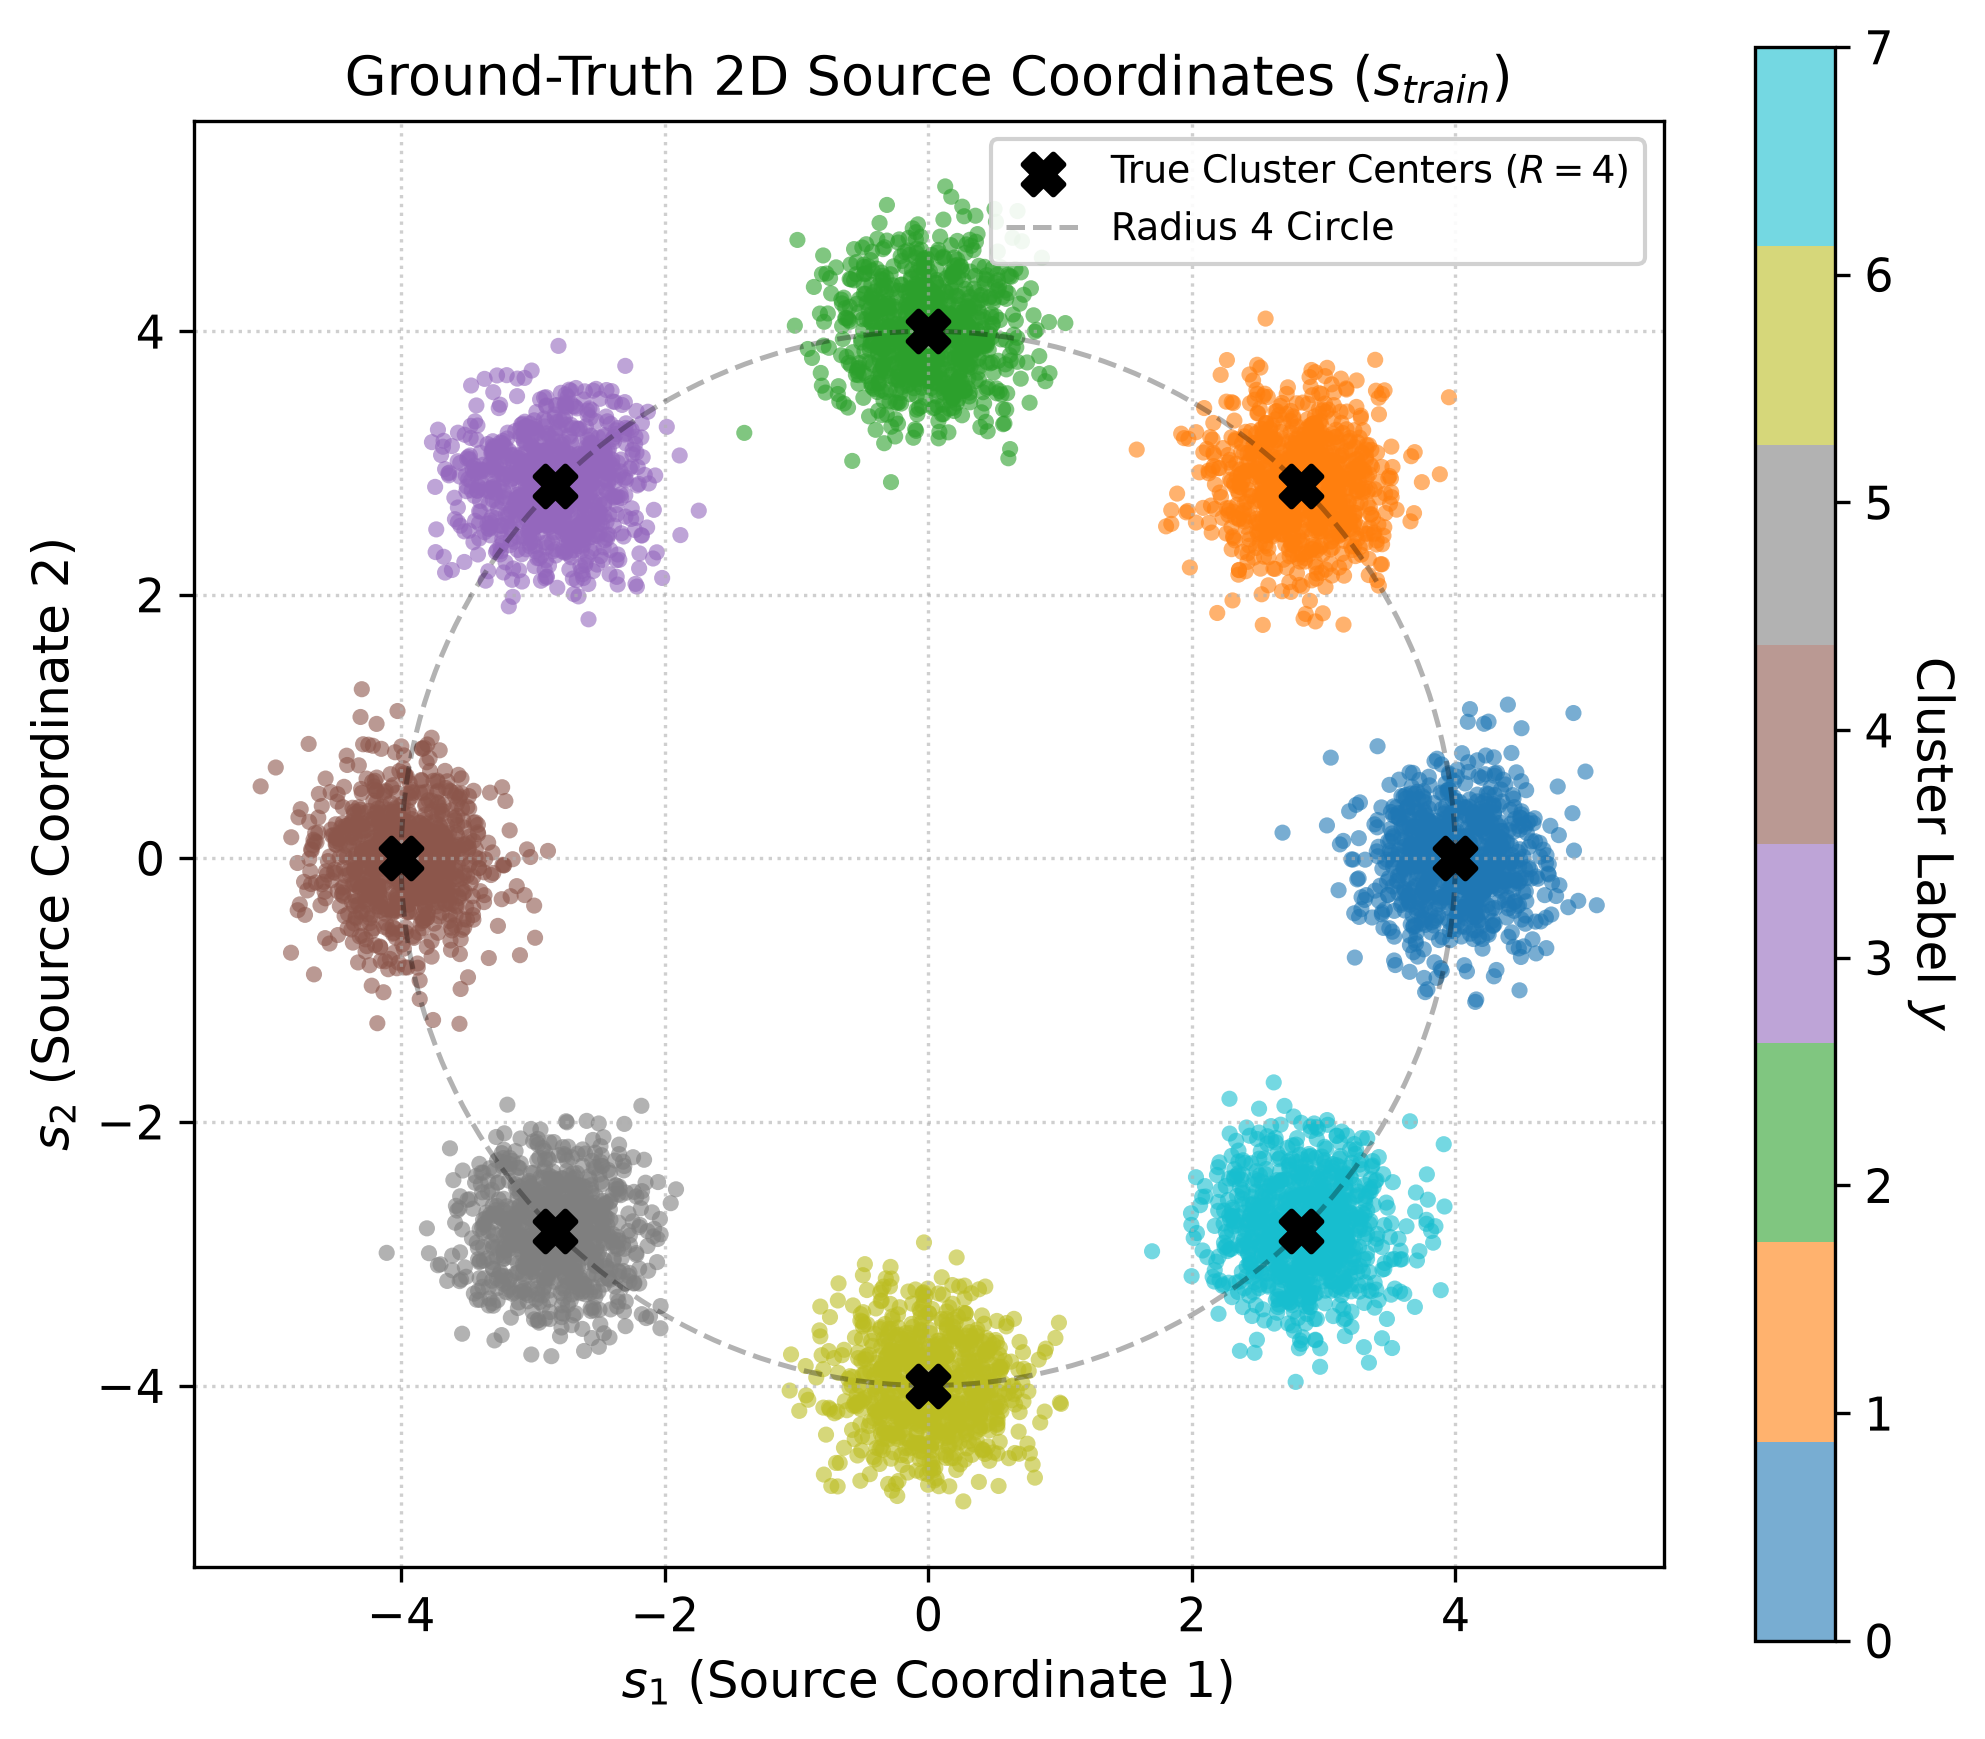

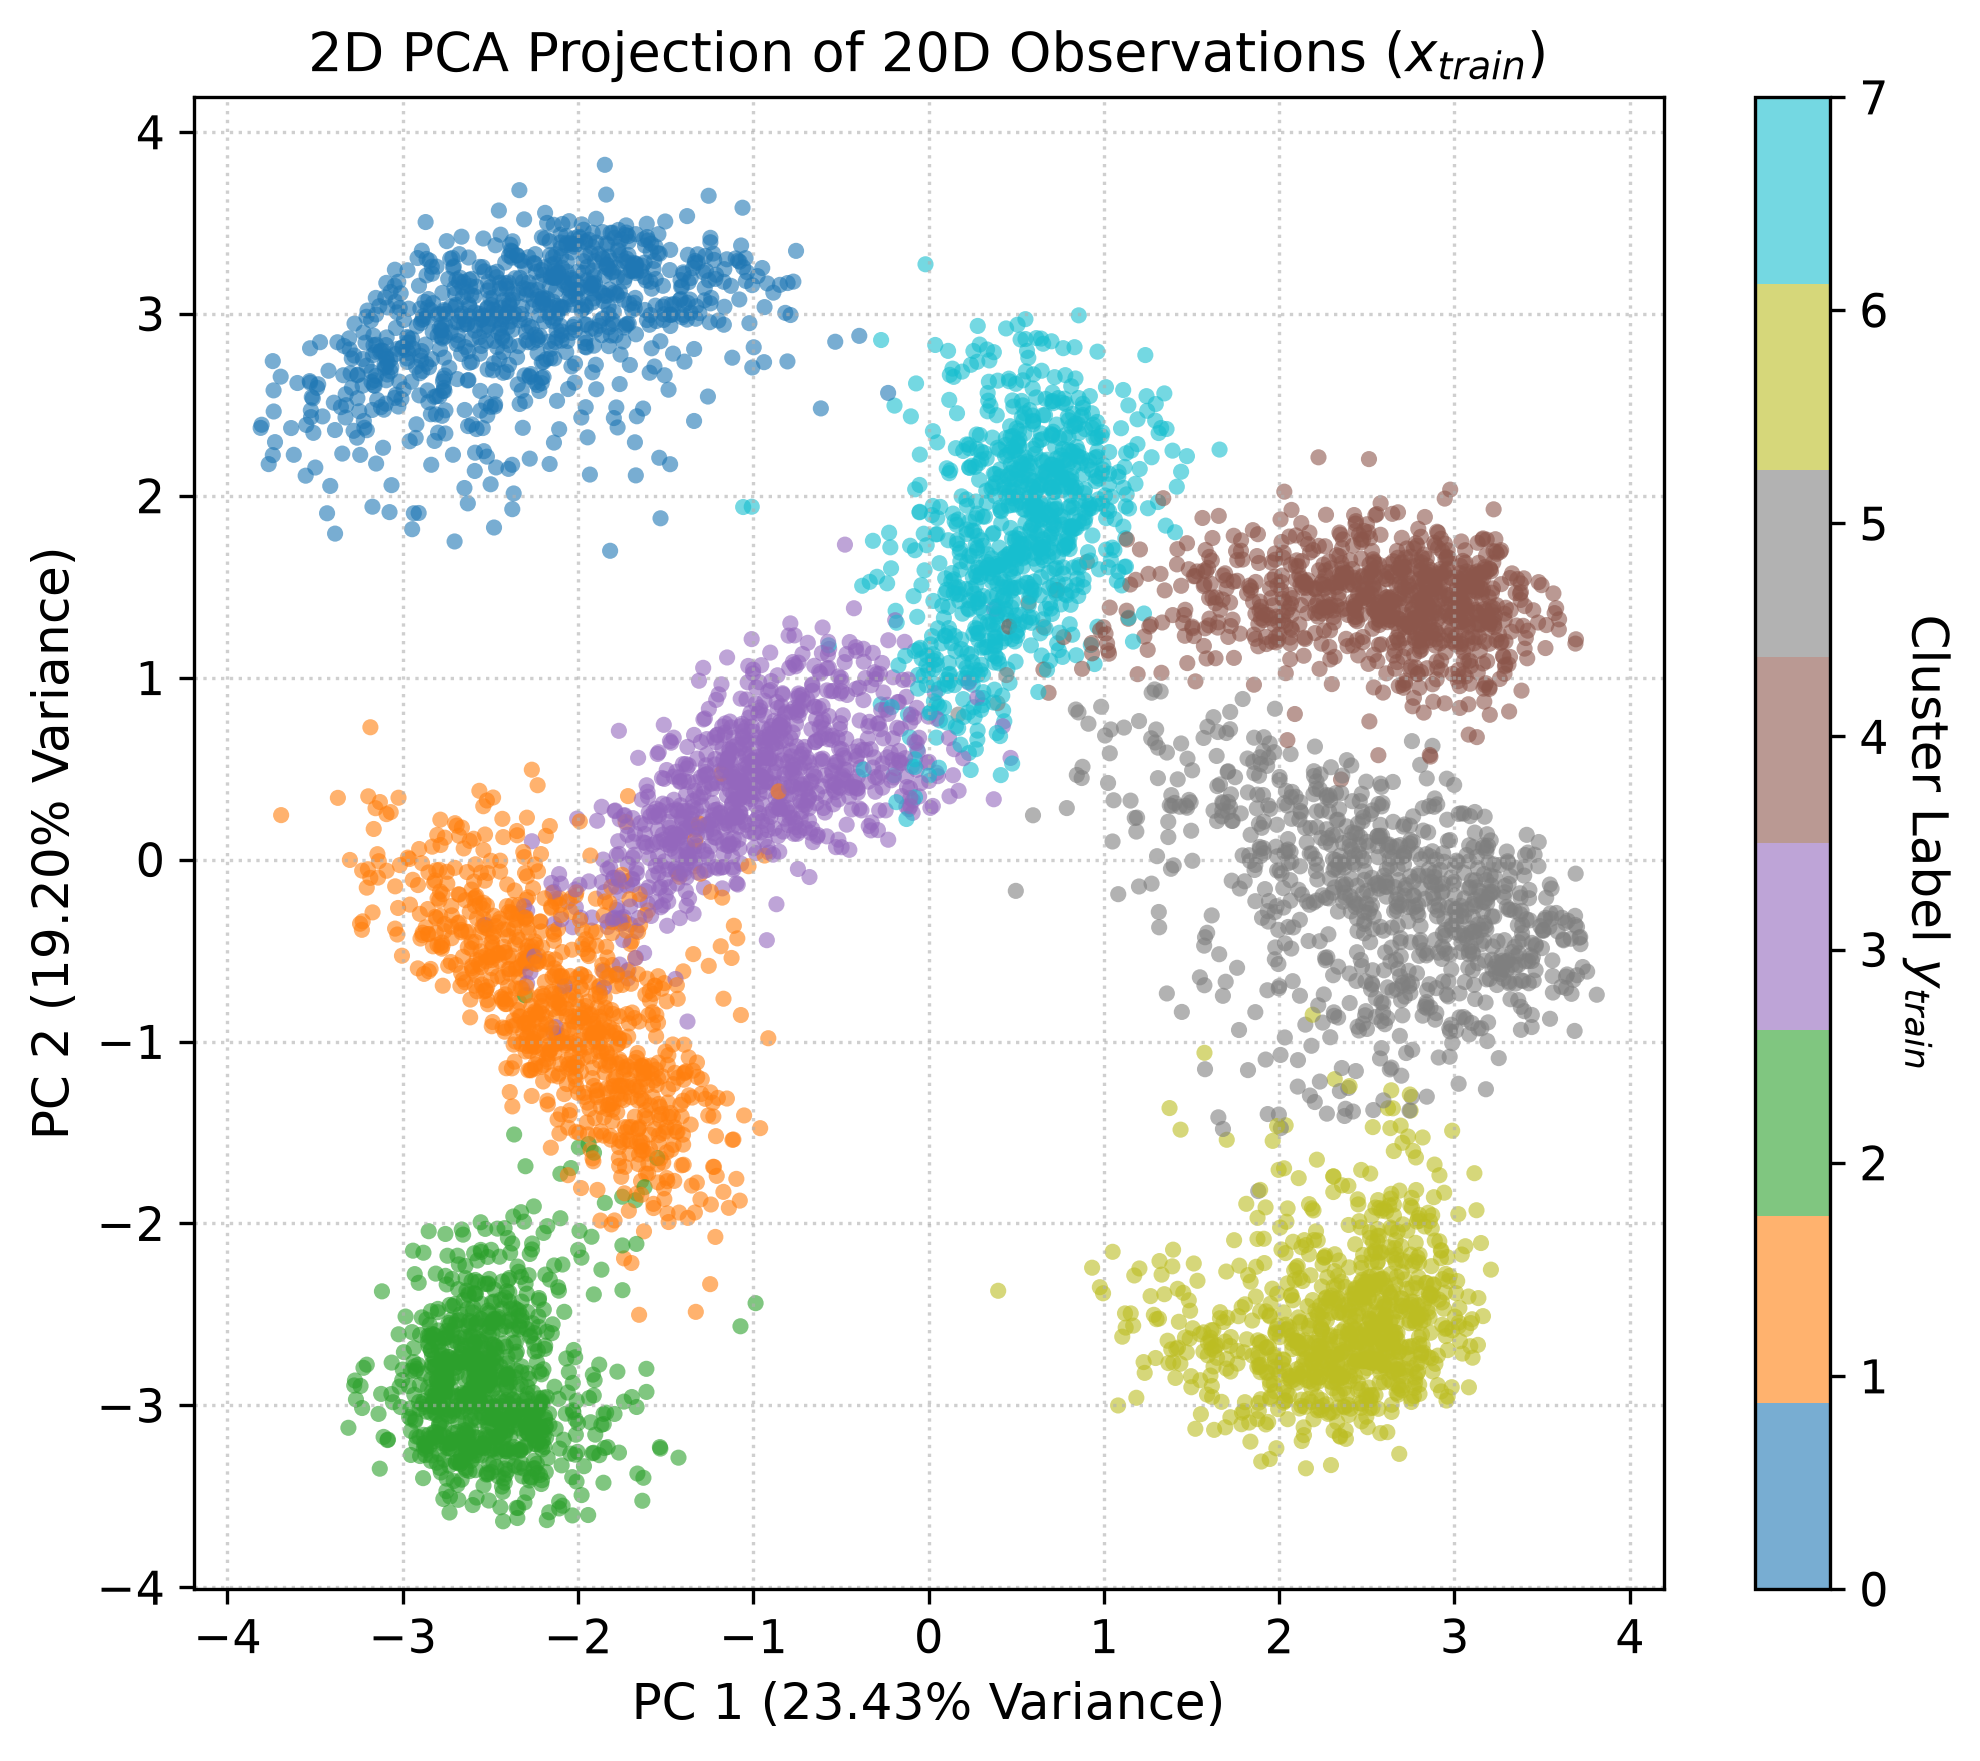

In [2]:
splits = load_dataset()
print("Dataset Splitting Summary:")
print(f"  - x_train shape: {splits.x_train.shape}, y_train shape: {splits.y_train.shape}")
print(f"  - x_val shape:   {splits.x_val.shape}, y_val shape:   {splits.y_val.shape}")
print(f"  - x_test shape:  {splits.x_test.shape}, y_test shape:  {splits.y_test.shape}")

print("\nVisualizing Ground Truth 2D Source Coordinates and Training Set PCA Projection:")
fig_dir = Path("results/figures")
display(Image(filename=str(fig_dir / "source_2d_scatter.png"), width=700))
display(Image(filename=str(fig_dir / "train_pca_2d_scatter.png"), width=700))


## Stage 2: VAE Architecture & Loss Formulations
- **Encoder**: $20 \to 128 \to 128 \to 2$, with ReLU activations, outputting mean $\mu_\phi(x)$ and log-variance $\log\sigma_\phi^2(x)$.
- **Decoder**: $2 \to 128 \to 128 \to 20$, with ReLU activations, outputting the reconstructed mean $\mu_\theta(z)$.
- **Observation Model**: Isotropic Gaussian likelihood with fixed $\sigma_x = 0.30$:
$$\mathcal{L}_{\text{recon}}(x) = \frac{1}{2\sigma_x^2} \|x - \mu_\theta(z)\|^2 + \frac{D}{2}\log(2\pi\sigma_x^2)$$
For $D=20, \sigma_x=0.30$, the scaling factor is $\frac{1}{2 \times 0.09} = \frac{1}{0.18} \approx 5.5556$, and the constant is $\approx -5.7006$.
- **KL Divergence**:
  - **Model A**: Analytical closed-form Gaussian KL:
  $$D_{\text{KL}}(q_\phi(z|x) \parallel \mathcal{N}(0, I)) = -\frac{1}{2} \sum_{j=1}^2 \left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$
  - **Models B, C, D**: Single-sample Monte Carlo KL with numerically stable `logsumexp`:
  $$D_{\text{KL}} \approx \log q_\phi(z|x) - \log p(z), \quad z \sim q_\phi(z|x)$$


## Stage 3 & 4: Model Checkpoints & Training Dynamics
All models were trained on `cuda:0` using Adam optimizer (learning rate $10^{-3}$, batch size 64) with early stopping (patience 15 epochs on validation total loss) over a maximum of 100 epochs.
Let us restore the best checkpoints and inspect their parameters.

> **Training Execution Command**:
> ```bash
> python -m src.training.run_experiments --device cuda:0
> ```


In [3]:
models = {}
config = ProjectConfig()
for m_type in ["A", "B", "C", "D"]:
    ckpt_path = Path("checkpoints") / f"model_{m_type}_best.pt"
    model = build_vae(m_type, config=config).to(device)
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()
    models[m_type] = model
    epoch = ckpt.get("epoch", ckpt.get("metadata", {}).get("best_epoch", "N/A"))
    best_loss = ckpt.get("val_loss", ckpt.get("metadata", {}).get("best_val_loss", 0.0))
    print(f"Loaded Model {m_type}: Best Epoch = {epoch}, Val Loss = {best_loss:.4f}")

# Inspect learned prior parameters for Models C and D
print("\n--- Model C Learned Prior Parameters (8 Components) ---")
print("Learned Component Centers (2D):\n", models["C"].prior.centers.detach().cpu().numpy())
print("Learned Component Stds (2D):\n", torch.exp(models["C"].prior.log_stds).detach().cpu().numpy())

print("\n--- Model D Learned Prior Parameters (4 Components) ---")
print("Learned Component Centers (2D):\n", models["D"].prior.centers.detach().cpu().numpy())
print("Learned Component Stds (2D):\n", torch.exp(models["D"].prior.log_stds).detach().cpu().numpy())


Loaded Model A: Best Epoch = 99, Val Loss = 9.4525
Loaded Model B: Best Epoch = 97, Val Loss = 9.4750
Loaded Model C: Best Epoch = 100, Val Loss = 9.1993
Loaded Model D: Best Epoch = 99, Val Loss = 9.2331

--- Model C Learned Prior Parameters (8 Components) ---
Learned Component Centers (2D):
 [[-1.0607187  -1.1330317 ]
 [ 1.3042405  -1.6099863 ]
 [ 0.7791957   2.1878002 ]
 [-0.14052975 -2.8637738 ]
 [ 0.8816666   0.32955167]
 [-0.9094471   0.7127307 ]
 [-2.9883225  -1.4862499 ]
 [ 2.2510548  -0.30330607]]
Learned Component Stds (2D):
 [[0.22873671 0.2844673 ]
 [0.32341596 0.39463148]
 [0.397024   0.37043163]
 [0.27179343 0.3990946 ]
 [1.0698948  0.30687907]
 [0.75497043 0.24616821]
 [0.14755224 0.4904548 ]
 [0.40237787 0.24388066]]

--- Model D Learned Prior Parameters (4 Components) ---
Learned Component Centers (2D):
 [[-1.0685729  -1.3536565 ]
 [-1.0763476   1.2132018 ]
 [ 0.9913224  -2.524873  ]
 [ 1.3822854   0.73556614]]
Learned Component Stds (2D):
 [[0.5783784  0.39227337]
 [0

### Training & Validation Learning Curves
The plot below illustrates the training and validation trajectories across all 4 models:
1. **Total ELBO Loss**
2. **Reconstruction Loss (NLL)**
3. **KL Divergence**


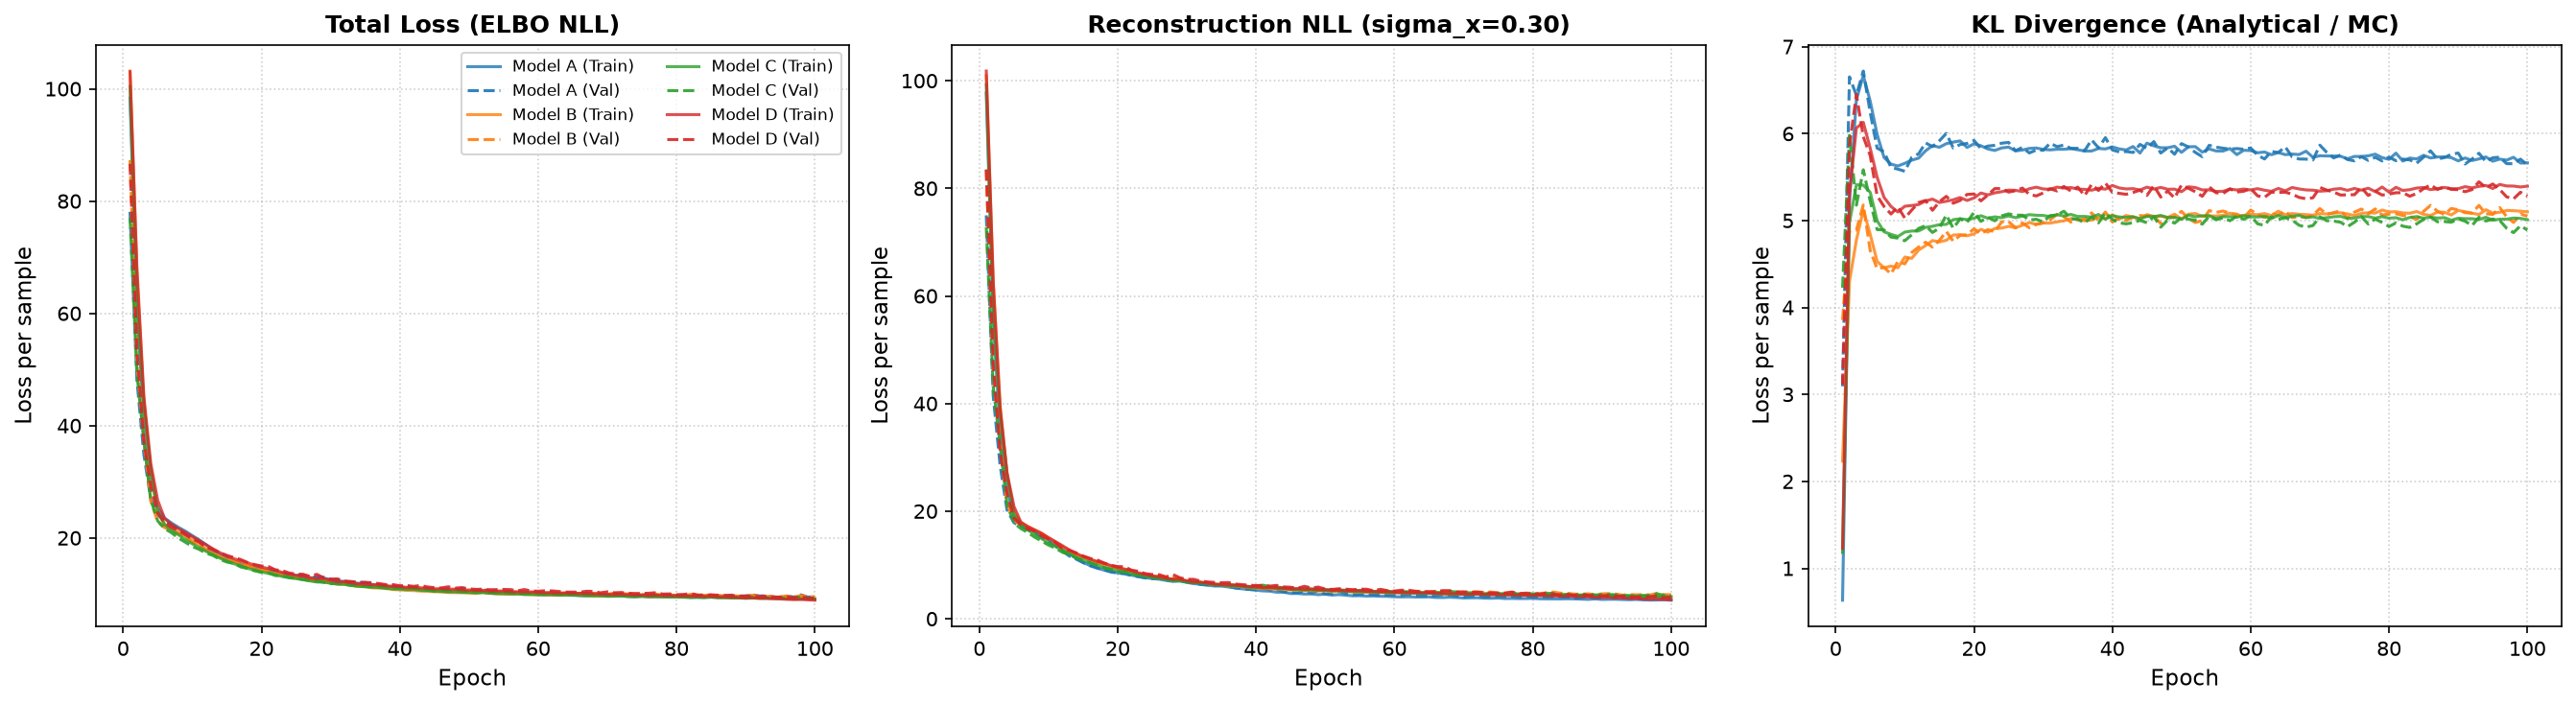

In [4]:
display(Image(filename=str(fig_dir / "learning_curves_all_models.png"), width=900))


## Stage 5: Evaluation & Comparative Analysis

> **Official Evaluation Execution Command**:
> ```bash
> python -m src.evaluation.run_evaluation --device cuda:0 --seed 42
> ```

### 1. Test Reconstruction Error
Reconstruction error is evaluated strictly on the unseen test set ($N=1,440$) using the deterministic posterior mean $\mu_\phi(x)$ passed to the decoder $\mu_\theta(\mu_\phi(x))$:
- **MSE Per Element**: $\frac{1}{N \cdot D} \sum_{i=1}^N \|x^{(i)} - \hat{x}^{(i)}\|^2$
- **Mean Squared $L_2$ Per Sample**: $\frac{1}{N} \sum_{i=1}^N \|x^{(i)} - \hat{x}^{(i)}\|^2 = D \times \text{MSE}_{\text{per\_element}}$


In [5]:
metrics_dir = Path("results/metrics")
eval_df = pd.read_csv(metrics_dir / "evaluation_summary.csv")

recon_table = eval_df[["model_type", "checkpoint_epoch", "mse_per_element", "mean_squared_l2_per_sample"]].copy()
recon_table.columns = ["Model", "Best Epoch", "MSE Per Element", "Mean Squared L2 Per Sample"]
display(recon_table.style.format({
    "MSE Per Element": "{:.5f}",
    "Mean Squared L2 Per Sample": "{:.4f}"
}))


,Model,Best Epoch,MSE Per Element,Mean Squared L2 Per Sample
0,A,99,0.07802,1.5604
1,B,97,0.08246,1.6492
2,C,100,0.08221,1.6442
3,D,99,0.07764,1.5528


### 2. Prior Sampling & PCA Projection
For each model, exactly 2,000 synthetic observations are sampled from the prior $z \sim p(z)$ and deterministically decoded $\hat{x} = \mu_\theta(z)$.
Both real test samples ($N=1,440$) and generated samples ($N=2,000$) are projected onto the **canonical Phase 1 PCA space** fitted strictly on the training set:


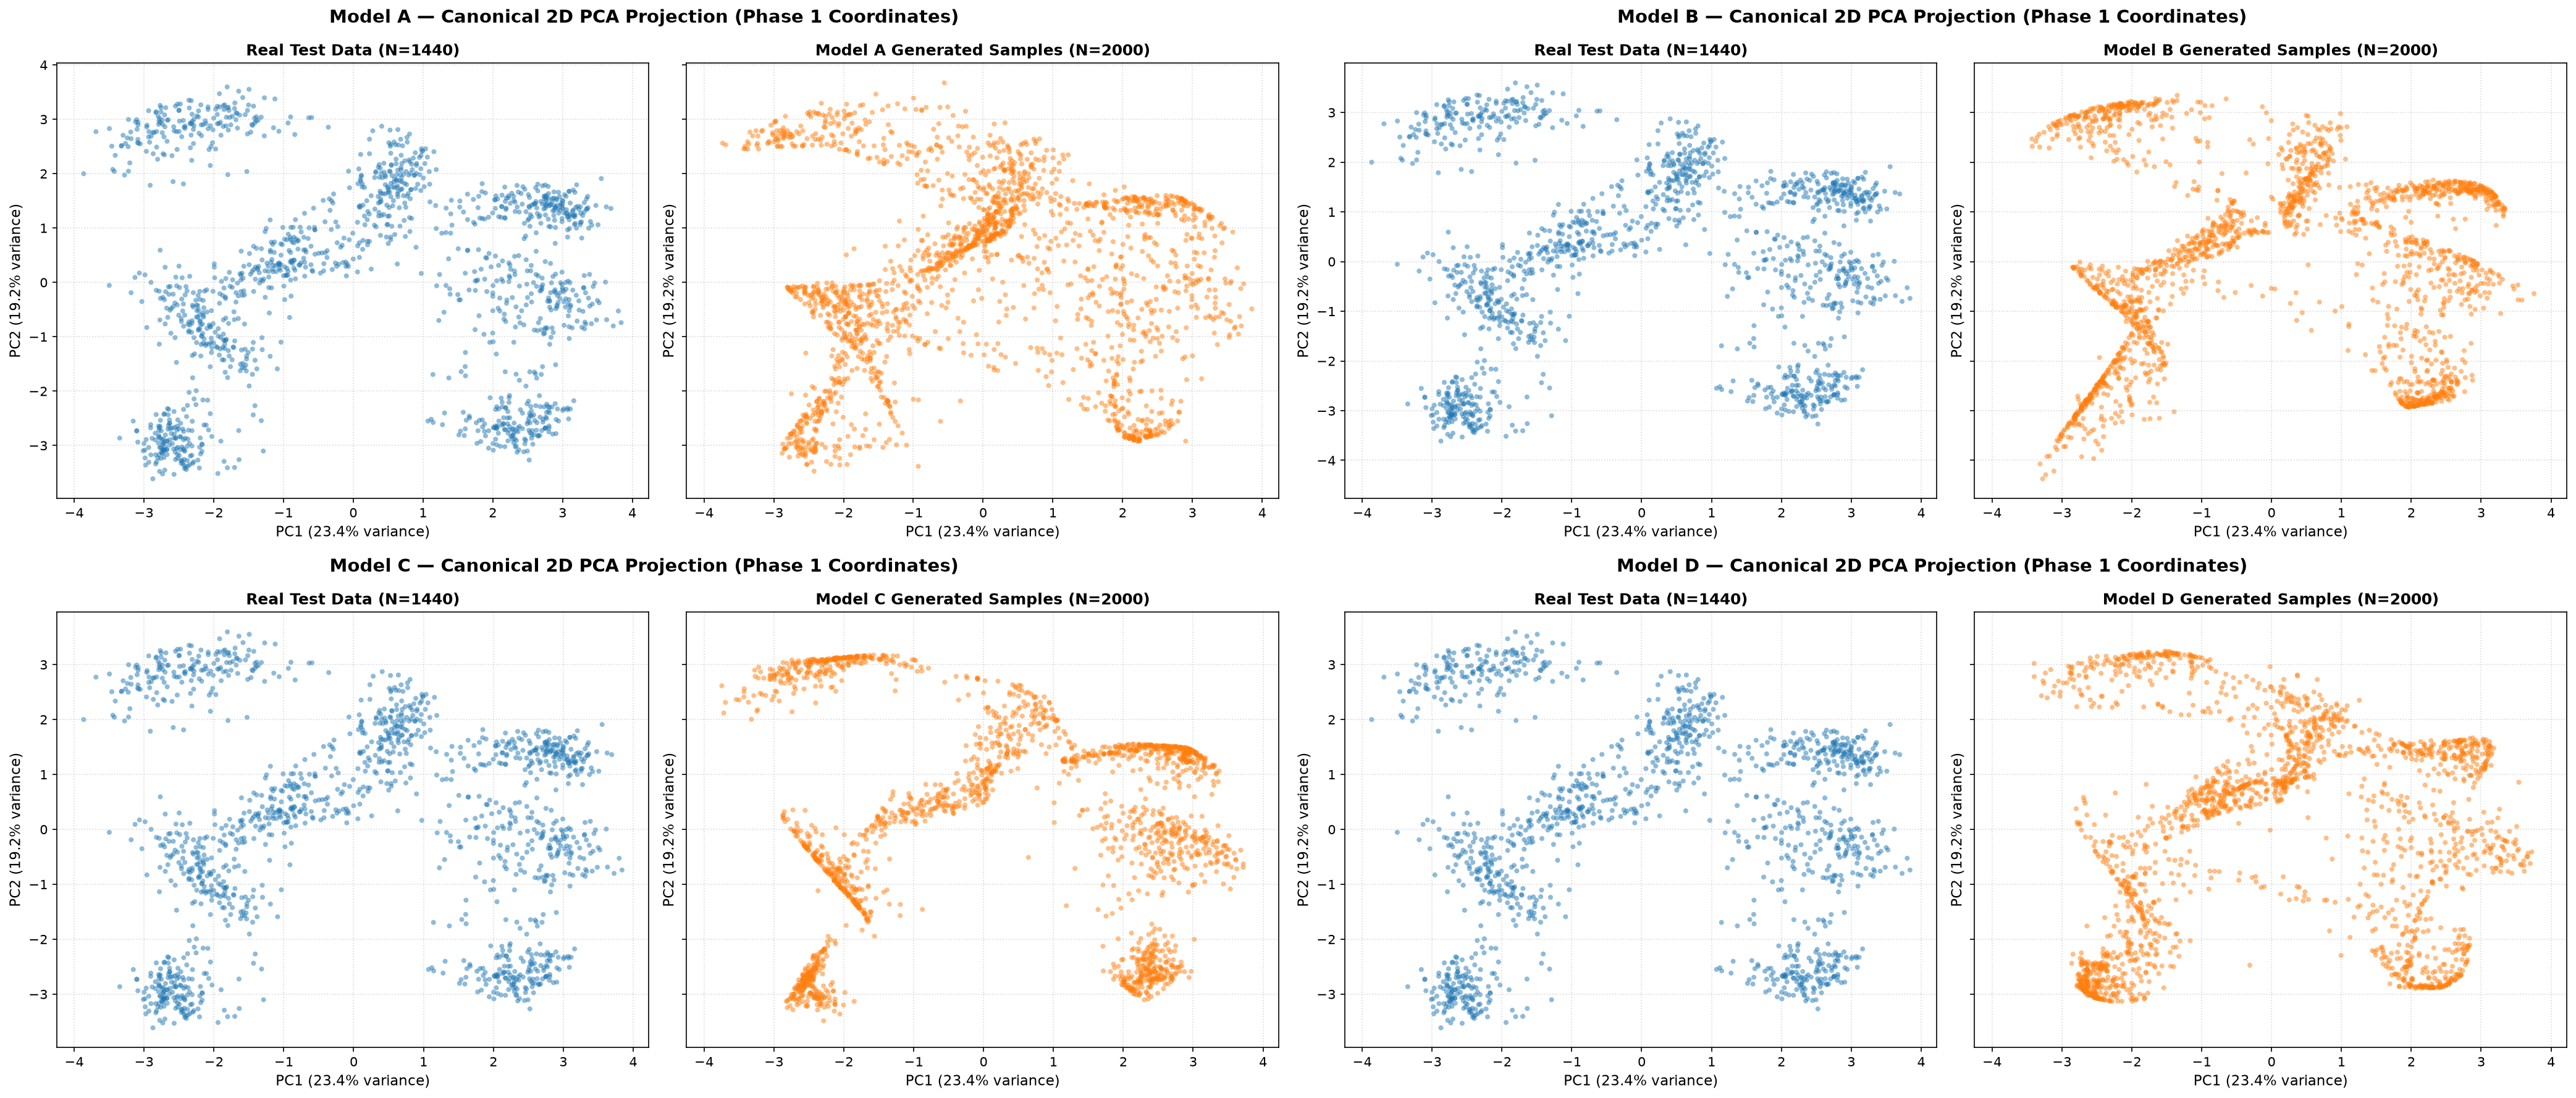

In [6]:
display(Image(filename=str(fig_dir / "pca_test_vs_generated_all_grid.png"), width=950))


### 3. Latent Space Geometry & Prior Densities
Below, we visualize the encoded test set distributions ($z \sim q_\phi(z|x)$) alongside each model's prior components / density contours:


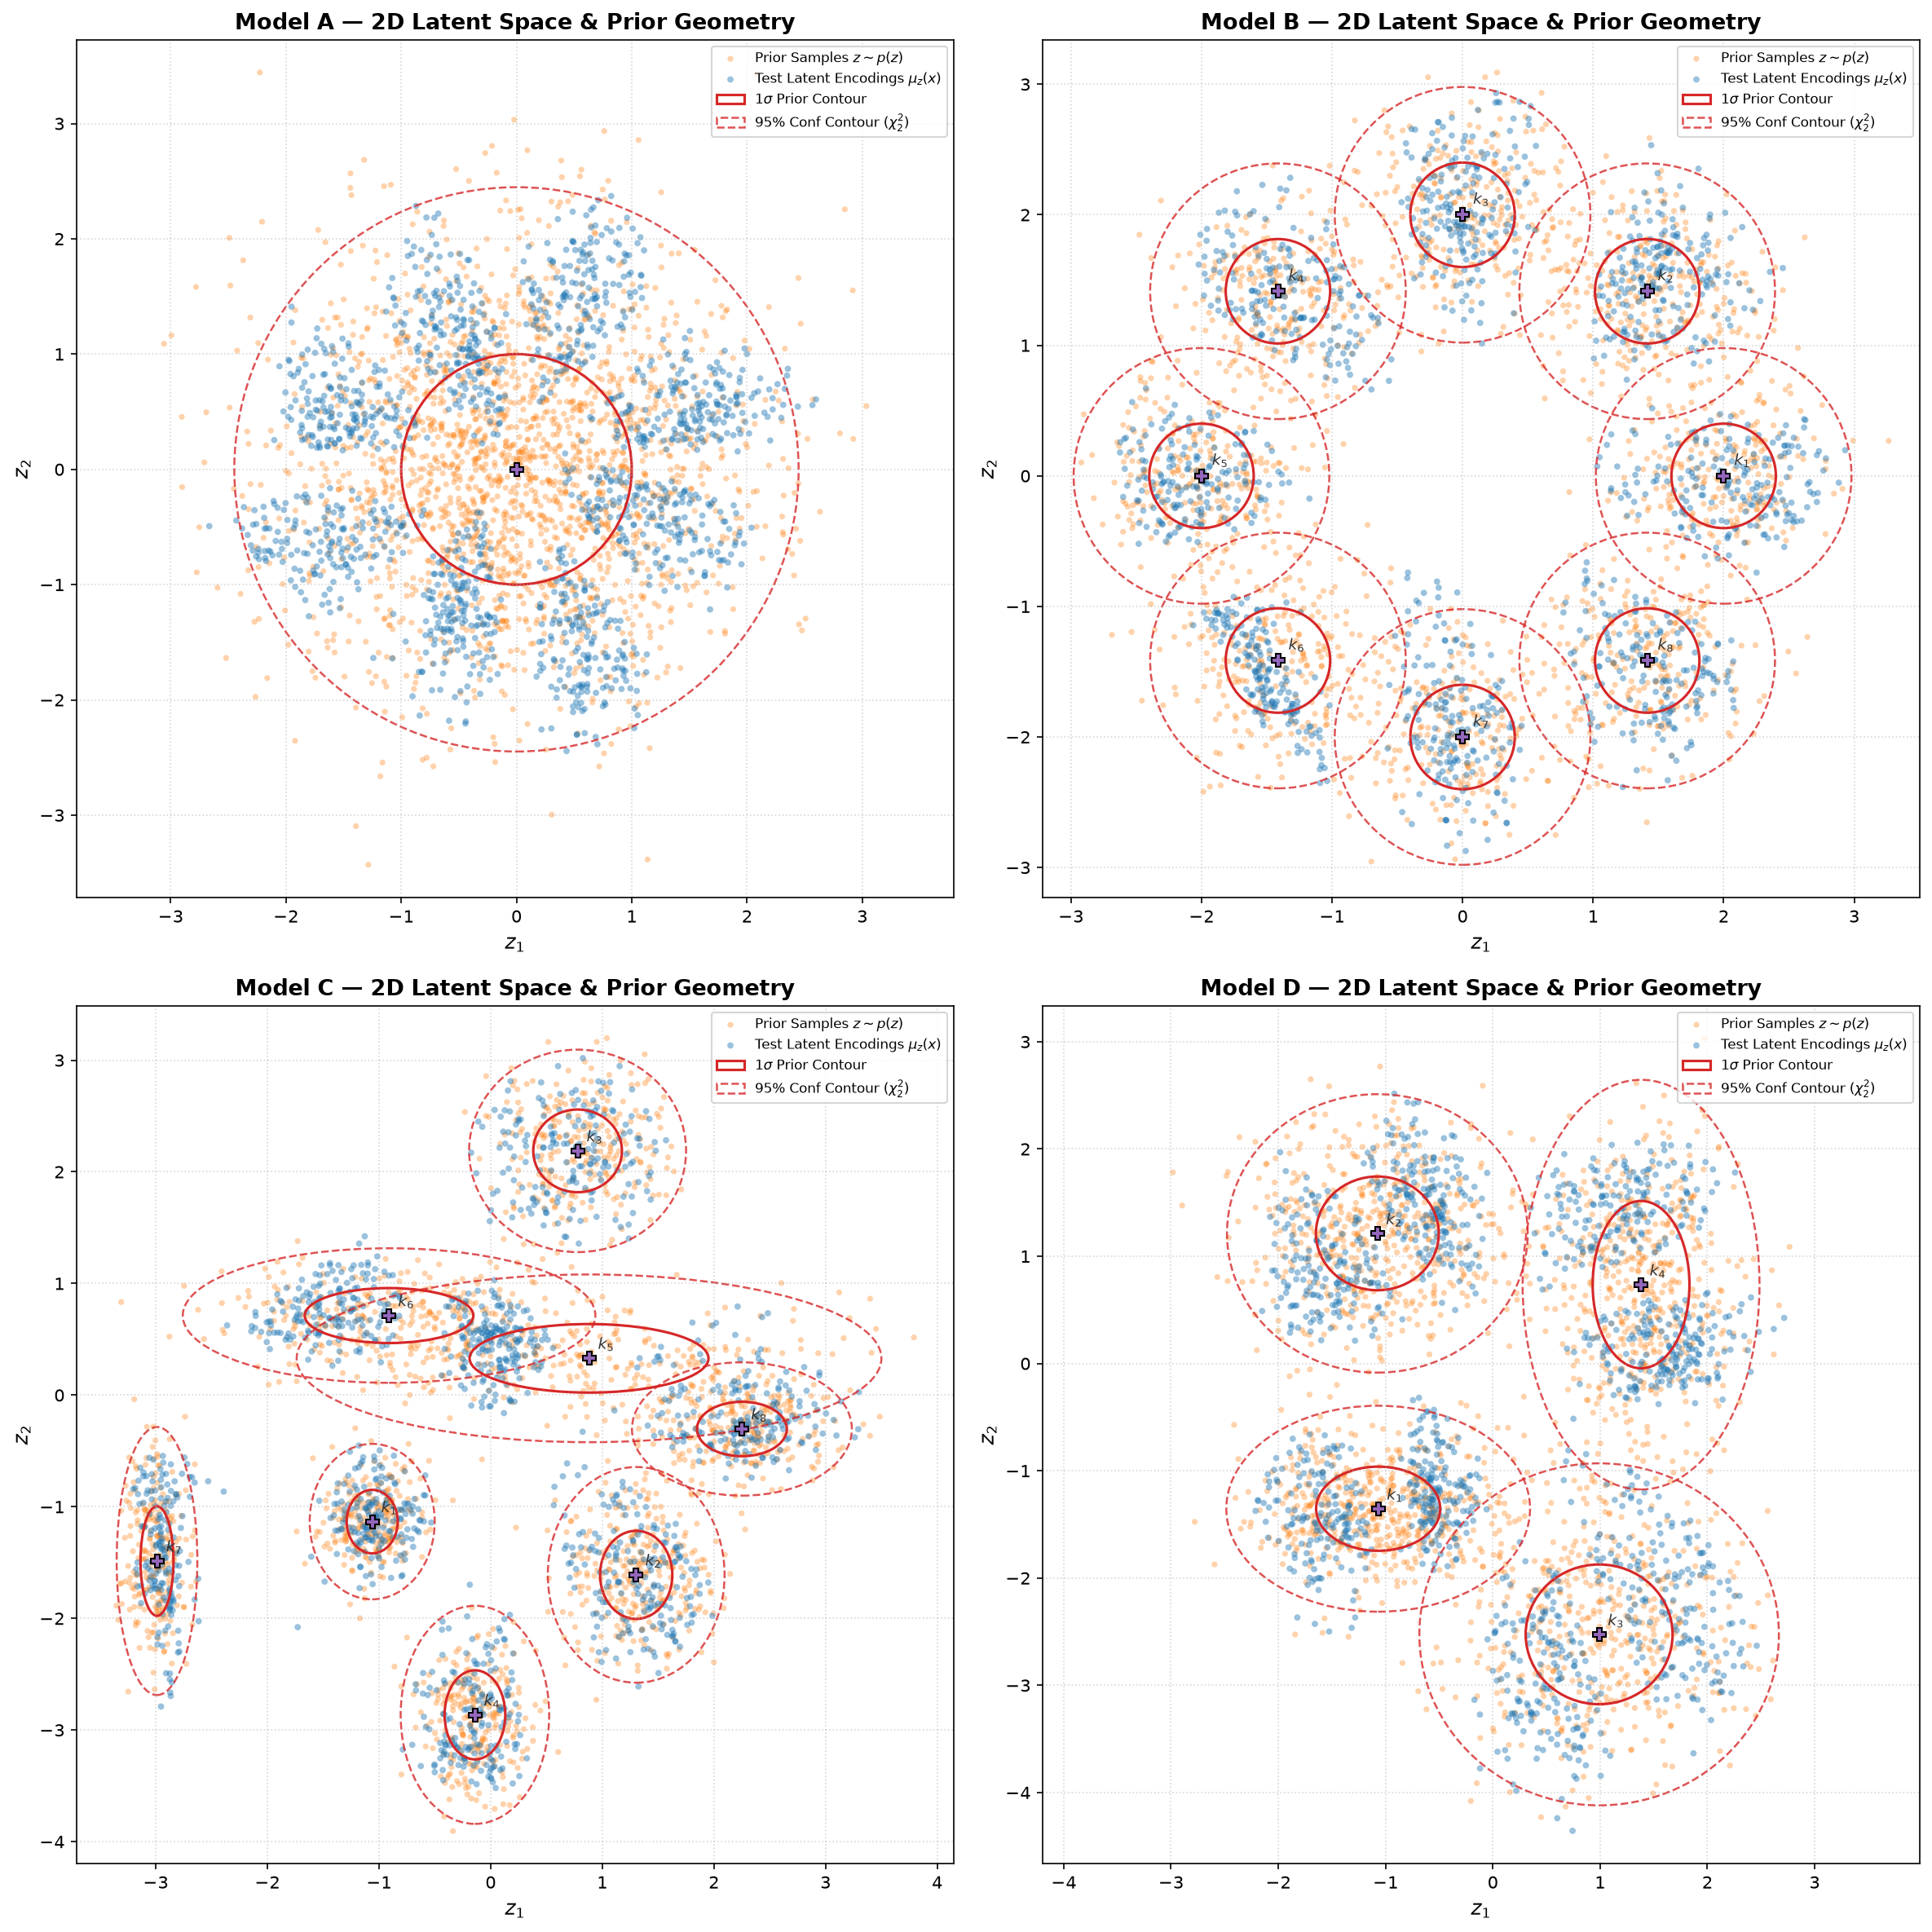

In [7]:
display(Image(filename=str(fig_dir / "latent_space_all_grid.png"), width=800))


### 4. Quantitative Distribution Matching & Cluster Coverage
- **Maximum Mean Discrepancy ($\text{MMD}^2$)**: Computed with the unbiased minimum-variance estimator using an RBF Gaussian kernel:
  - **Data Space**: Median pairwise Euclidean distance on training subset ($N=600$): $\sigma_{\text{data}} = 6.4250$.
  - **Latent Space**: Median pairwise distance on 600 standard normal draws: $\sigma_{\text{latent}} = 1.6704$.
  - Evaluated on equal sample sizes ($m = n = 1,440$).
- **20D Cluster Validity & Coverage**:
  - Reference cluster centroids $C_k$ and 95th-percentile acceptance radii $R_k$ computed strictly on the validation set in 20D.
  - A generated sample is valid if its distance to the nearest centroid is $\le R_k$.
  - A cluster is covered if it contains $\ge 20$ valid samples.


,Model,Data MMD^2 (sigma=6.425),Latent MMD^2 (sigma=1.670),20D Validity Rate (%),Covered Clusters (>=20)
0,A,0.006637,0.011161,80.10%,8/8
1,B,0.000943,-0.000372,95.25%,8/8
2,C,0.001995,0.003214,95.65%,8/8
3,D,0.001825,0.000588,93.00%,8/8


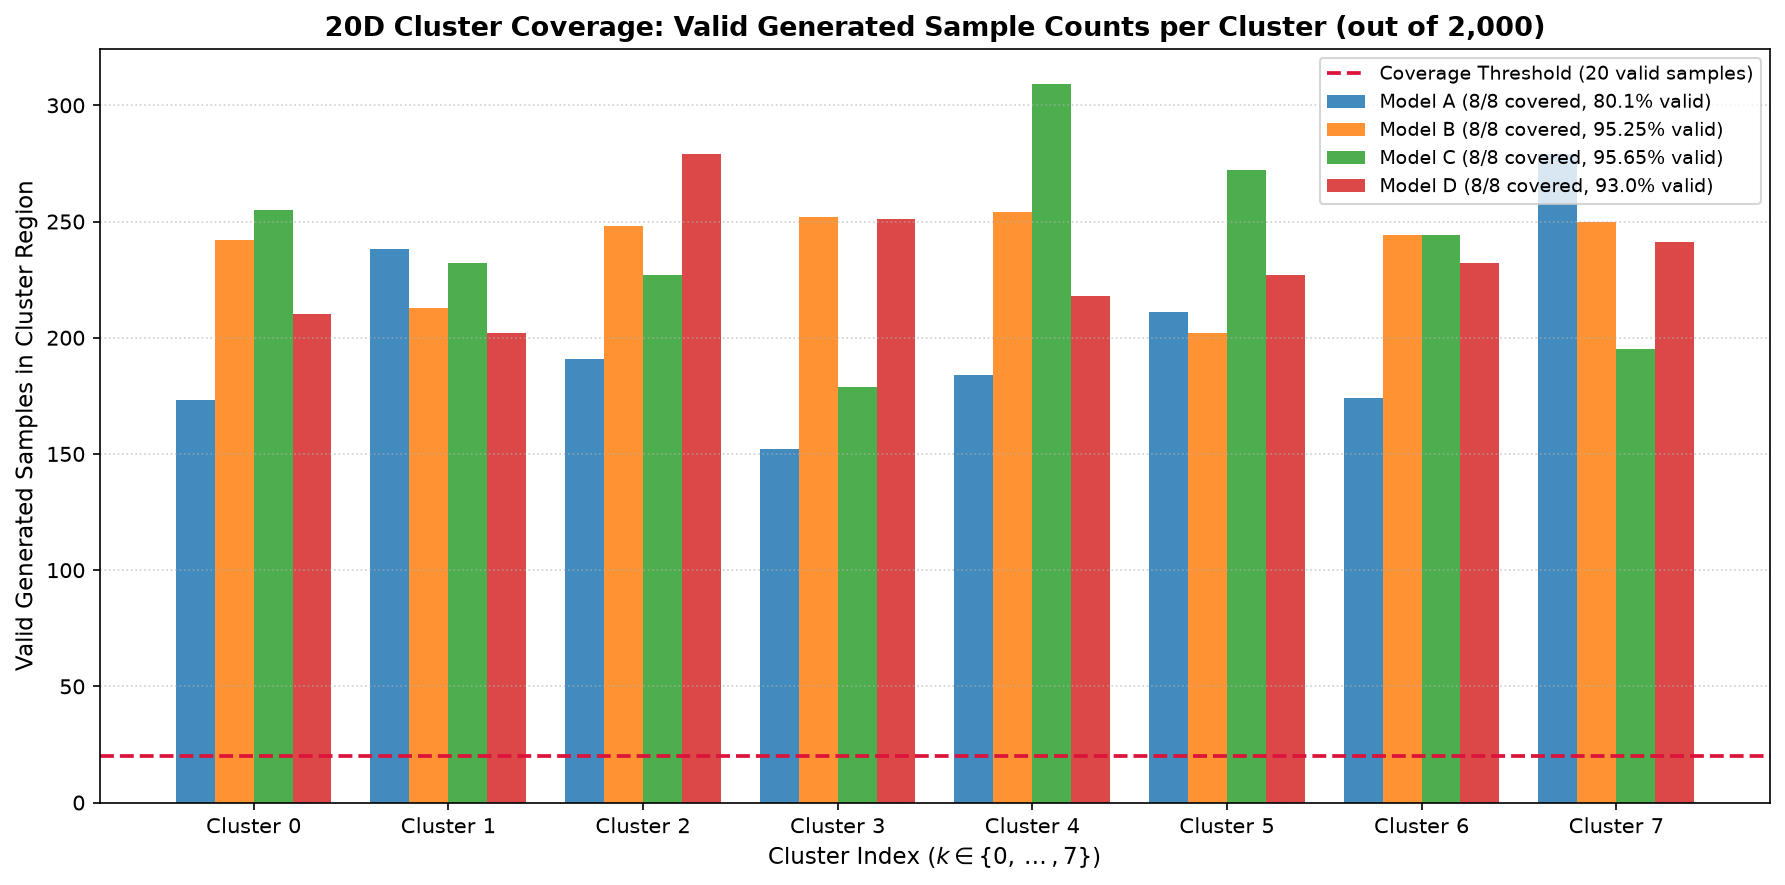

In [8]:
quant_table = eval_df[[
    "model_type", "data_mmd2", "latent_mmd2", "cluster_validity_rate_pct", "covered_clusters_count"
]].copy()
quant_table.columns = ["Model", "Data MMD^2 (sigma=6.425)", "Latent MMD^2 (sigma=1.670)", "20D Validity Rate (%)", "Covered Clusters (>=20)"]
display(quant_table.style.format({
    "Data MMD^2 (sigma=6.425)": "{:.6f}",
    "Latent MMD^2 (sigma=1.670)": "{:.6f}",
    "20D Validity Rate (%)": "{:.2f}%",
    "Covered Clusters (>=20)": "{}/8"
}))

display(Image(filename=str(fig_dir / "cluster_coverage_comparison.png"), width=750))


### 5. Mixture Component Assignments & Responsibilities
For the mixture models (B, C, D), we evaluate:
1. **Hard Assignment Proportions**: Proportion of test latent codes assigned to component $k$ via maximum prior density:
   $$k^*(z) = \arg\max_k \mathcal{N}(z; \mu_k, \Sigma_k)$$
2. **Mean Posterior Responsibilities**: Expected responsibility across test codes:
   $$\gamma_k(z) = \frac{\pi_k \mathcal{N}(z; \mu_k, \Sigma_k)}{\sum_{j} \pi_j \mathcal{N}(z; \mu_j, \Sigma_j)}$$


In [9]:
with open(metrics_dir / "component_assignments.json", "r") as f:
    comp_data = json.load(f)

for m in ["B", "C", "D"]:
    hard_p = comp_data[m]["hard_proportions"]
    mean_r = comp_data[m]["mean_responsibilities"]
    df_comp = pd.DataFrame({
        "Component": [f"k={k}" for k in hard_p.keys()],
        "Hard Assignment (%)": [f"{v * 100:.2f}%" for v in hard_p.values()],
        "Mean Responsibility (%)": [f"{mean_r[k] * 100:.2f}%" for k in hard_p.keys()]
    })
    print(f"\n--- Model {m} Component Utilization ---")
    display(df_comp)



--- Model B Component Utilization ---


,Component,Hard Assignment (%),Mean Responsibility (%)
0,k=0,13.12%,13.06%
1,k=1,13.68%,13.71%
2,k=2,13.19%,13.31%
3,k=3,12.50%,12.32%
4,k=4,11.88%,11.97%
5,k=5,11.74%,11.76%
6,k=6,12.01%,11.98%
7,k=7,11.88%,11.88%



--- Model C Component Utilization ---


,Component,Hard Assignment (%),Mean Responsibility (%)
0,k=0,12.22%,12.22%
1,k=1,13.06%,13.01%
2,k=2,12.50%,12.49%
3,k=3,11.88%,11.87%
4,k=4,10.00%,11.15%
5,k=5,17.36%,16.85%
6,k=6,11.53%,11.53%
7,k=7,11.46%,10.88%



--- Model D Component Utilization ---


,Component,Hard Assignment (%),Mean Responsibility (%)
0,k=0,23.75%,23.51%
1,k=1,25.07%,25.40%
2,k=2,24.51%,24.42%
3,k=3,26.67%,26.67%


## Master Synthesis & Research Question Answers

### 1. Reconstruction vs. Generation Quality Trade-Off
- **Model D** achieves the best reconstruction MSE ($0.07764$), followed by **Model A** ($0.07802$). Unimodal or low-component priors give the encoder maximum flexibility to position latent codes for optimal reconstruction.
- However, **Model B** and **Model C** achieve vastly superior generation quality (Data MMD$^2 \approx 0.0009 - 0.0019$ vs $0.0066$ for Model A; Validity Rate $> 95\%$ vs $80.1\%$ for Model A).
- Multi-modal priors eliminate the "prior hole" problem in unimodal VAEs, matching the true clustered structure of the data distribution.

### 2. Fixed GMM vs. Learnable GMM vs. VampPrior
- **Model B (Fixed GMM)** incorporates exact domain oracle knowledge ($r=2.0, \sigma=0.40$), yielding the best MMD scores.
- **Model C (Learnable GMM)** autonomously discovers 8 dispersed cluster centers in 2D latent space and achieves the highest 20D validity rate ($95.65\%$).
- **VampPrior** (Tomczak & Welling, 2018) couples the prior directly to the encoder via learned pseudo-inputs $u_k \in \mathbb{R}^{20}$ in data space: $p(z) = \frac{1}{K} \sum q_\phi(z|u_k)$, eliminating the need to parameterize Gaussian components directly in latent space.

### 3. Verification & Unit Testing Suite
All 57 mathematical contracts, loss functions, architecture modules, and evaluation metrics can be verified end-to-end via:
> **Unit Test Execution Command**:
> ```bash
> python -m unittest discover -s tests -v
> ```


---
*Notebook generation completed successfully.*
